In [37]:
import os, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture


RANDOM_STATE     = 42
MAX_MISSING_FRAC = 0.10
VARIANCE_TARGET  = 0.90
K_RANGE          = range(2, 9)
COV_TYPES        = ['spherical', 'diag', 'tied', 'full']
N_INIT           = 20
REG_COVAR_FRAC   = 0.01
N_SUBSAMPLES     = 100
SUBSAMPLE_FRAC   = 0.8

In [38]:
import sys

if "google.colab" in sys.modules:
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]

print("Using file:", DATA_FILE)

Saving FTSE 250 2021–2026 Dataset.csv to FTSE 250 2021–2026 Dataset.csv
Using file: FTSE 250 2021–2026 Dataset.csv


In [39]:
X_raw = pd.read_csv(DATA_FILE, index_col=0)
X_raw.columns = pd.to_datetime(X_raw.columns)

n_before = X_raw.shape[0]
frac_missing = X_raw.isna().sum(axis=1) / X_raw.shape[1]
tickers_dropped = frac_missing[frac_missing > MAX_MISSING_FRAC].index.tolist()

X_clean = X_raw.loc[frac_missing <= MAX_MISSING_FRAC].copy()
n_filled = int(X_clean.isna().sum().sum())
X_clean = X_clean.ffill(axis=1).bfill(axis=1)

print(f"Stocks before exclusion : {n_before}")
print(f"Dropped (>10% missing)  : {len(tickers_dropped)} {tickers_dropped}")
print(f"Gaps filled             : {n_filled}")
print(f"Stocks retained         : {X_clean.shape[0]}")
assert X_clean.isna().sum().sum() == 0, "Missing values remain after fill."

A = X_clean.values
print("Data matrix (stocks x days):", A.shape)

Stocks before exclusion : 241
Dropped (>10% missing)  : 0 []
Gaps filled             : 4
Stocks retained         : 241
Data matrix (stocks x days): (241, 1153)


In [40]:
pca = PCA(n_components=VARIANCE_TARGET, random_state=RANDOM_STATE)
X = pca.fit_transform(A)
d = X.shape[1]


REG_COVAR = REG_COVAR_FRAC * X.var(axis=0).mean()

print(f"PCA: {A.shape[1]} days -> {d} components ({VARIANCE_TARGET:.0%} of variance)")
print("Variance explained per PC:", np.round(pca.explained_variance_ratio_ * 100, 1))
print(f"Clustering matrix: {X.shape}   (n = {X.shape[0]} stocks, d = {d})")
print(f"reg_covar = {REG_COVAR:.3f}  ({REG_COVAR_FRAC:.0%} of mean PC variance)")

PCA: 1153 days -> 9 components (90% of variance)
Variance explained per PC: [48.  18.4  8.4  5.6  3.4  2.4  2.1  1.5  1.1]
Clustering matrix: (241, 9)   (n = 241 stocks, d = 9)
reg_covar = 0.981  (1% of mean PC variance)


In [41]:
def make_gmm(k, cov, n_init=N_INIT, seed=RANDOM_STATE):
    return GaussianMixture(n_components=k, covariance_type=cov, n_init=n_init,
                           reg_covar=REG_COVAR, max_iter=500, random_state=seed)


_CM_CACHE = {}

def consensus_matrix(X, k, cov, B=N_SUBSAMPLES, frac=SUBSAMPLE_FRAC, n_init=5, seed=RANDOM_STATE):

    key = (X.shape, hash(X.tobytes()), k, cov, B, frac, n_init, seed, REG_COVAR)
    if key in _CM_CACHE:
        return _CM_CACHE[key]
    rng = np.random.default_rng(seed)
    n = X.shape[0]; m = int(frac * n)
    together = np.zeros((n, n)); sampled = np.zeros((n, n)); n_failed = 0
    for b in range(B):
        idx = rng.choice(n, m, replace=False)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                lab = make_gmm(k, cov, n_init, seed + b).fit_predict(X[idx])
        except ValueError:
            n_failed += 1
            continue
        ix = np.ix_(idx, idx)
        together[ix] += (lab[:, None] == lab[None, :])
        sampled[ix] += 1
    if n_failed:
        print(f"  note: {n_failed}/{B} subsample fits failed for k={k}, '{cov}' (skipped)")
    M = np.divide(together, sampled, out=np.zeros((n, n)), where=sampled > 0)
    np.fill_diagonal(M, 1.0)
    _CM_CACHE[key] = M
    return M


def cluster_consensus(M, labels, n_clusters=None):

    labels = np.asarray(labels)
    ids = np.unique(labels) if n_clusters is None else range(n_clusters)
    out = []
    for c in ids:
        idx = np.where(labels == c)[0]
        if len(idx) < 2:
            out.append(np.nan); continue
        out.append(M[np.ix_(idx, idx)][np.triu_indices(len(idx), 1)].mean())
    return np.array(out)


def cdf_area(M):

    v = np.sort(M[np.triu_indices(M.shape[0], 1)])
    h = np.arange(1, len(v) + 1) / len(v)
    nxt = np.append(v[1:], 1.0)
    return float(np.sum(h * (nxt - v)))


def pac(M, lo=0.1, hi=0.9):

    v = M[np.triu_indices(M.shape[0], 1)]
    return float(np.mean((v > lo) & (v < hi)))


print("Helpers defined.")

Helpers defined.


In [42]:
rows = []
for cov in COV_TYPES:
    for k in K_RANGE:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = make_gmm(k, cov)
            model.fit(X)
        rows.append({
            'covariance_type': cov, 'k': k,
            'bic': model.bic(X),
            'log_likelihood': model.score(X) * X.shape[0],
            'n_params': model._n_parameters(),
            'n_iter': int(model.n_iter_),
            'converged': bool(model.converged_),
        })
results_df = pd.DataFrame(rows)


valid_df = results_df[results_df['converged']]
assert len(valid_df), "No fit converged - raise max_iter or REG_COVAR_FRAC."


best_row = valid_df.loc[valid_df['bic'].idxmin()]
naive_row = results_df.loc[results_df['bic'].idxmin()]

print(f"Fits tried: {len(results_df)}   converged: {len(valid_df)}   not converged: {len(results_df) - len(valid_df)}")
print()
print(f"BIC-selected (converged only): k = {int(best_row['k'])}, '{best_row['covariance_type']}'  "
      f"(BIC {best_row['bic']:.0f}, log-likelihood {best_row['log_likelihood']:.0f})")
if int(best_row['k']) in (min(K_RANGE), max(K_RANGE)):
    print("WARNING: BIC optimum is at the edge of K_RANGE - widen the range or treat with caution.")
if not naive_row['converged']:
    print(f"\nWithout the convergence check BIC would have picked k = {int(naive_row['k'])}, "
          f"'{naive_row['covariance_type']}' (EM did not converge).")

print("\nTop 8 converged models by BIC:")
display(valid_df.sort_values('bic').head(8)[['covariance_type', 'k', 'bic', 'log_likelihood',
                                              'n_params', 'n_iter']].round(3).reset_index(drop=True))
print("Fits that did not converge:")
display(results_df[~results_df['converged']][['covariance_type', 'k', 'bic', 'log_likelihood', 'n_iter']]
        .round(0).reset_index(drop=True))

Fits tried: 28   converged: 28   not converged: 0

BIC-selected (converged only): k = 3, 'diag'  (BIC 14267, log-likelihood -6980)

Top 8 converged models by BIC:


,covariance_type,k,bic,log_likelihood,n_params,n_iter
0,diag,3,14266.818,-6979.834,56,13
1,diag,4,14296.080,-6942.360,75,26
2,diag,5,14325.201,-6904.815,94,20
3,diag,2,14345.926,-7071.494,37,13
4,diag,6,14391.717,-6885.968,113,22
5,diag,7,14452.701,-6864.354,132,18
6,diag,8,14491.355,-6831.576,151,22
7,full,2,14573.111,-6987.634,109,27


Fits that did not converge:


,covariance_type,k,bic,log_likelihood,n_iter


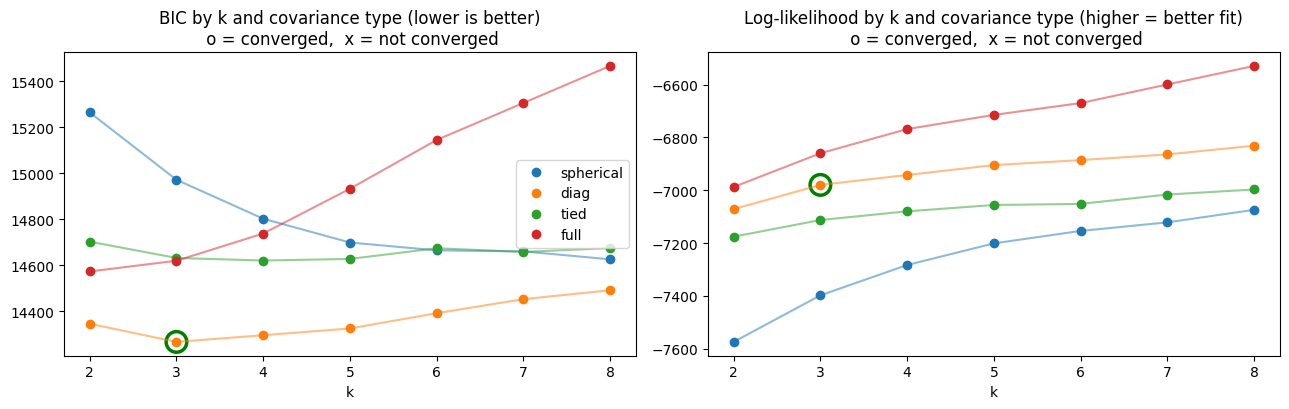

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cols_plot = [('bic', 'BIC', 'lower is better'), ('log_likelihood', 'Log-likelihood', 'higher = better fit')]
for ci, cov in enumerate(COV_TYPES):
    sub_c = results_df[results_df['covariance_type'] == cov]
    for ax, (col, _, _) in zip(axes, cols_plot):
        ax.plot(sub_c['k'], sub_c[col], '-', alpha=0.5, color=f'C{ci}')
        ok = sub_c[sub_c['converged']]; bad = sub_c[~sub_c['converged']]
        ax.plot(ok['k'], ok[col], 'o', color=f'C{ci}', label=cov)
        ax.plot(bad['k'], bad[col], 'x', color=f'C{ci}', ms=8, mew=2)
for ax, (_, name, note) in zip(axes, cols_plot):
    ax.set_title(f'{name} by k and covariance type ({note})\n o = converged,  x = not converged')
    ax.set_xlabel('k'); ax.set_xticks(list(K_RANGE))
axes[0].legend()
axes[0].scatter([best_row['k']], [best_row['bic']], s=220, facecolors='none', edgecolors='green', linewidths=2.5)
axes[1].scatter([best_row['k']], [best_row['log_likelihood']], s=220, facecolors='none', edgecolors='green', linewidths=2.5)
plt.tight_layout(); plt.show()

In [44]:
chosen_row = best_row

print("Selection rule for k (and covariance type):")
print("  CHECK 1 - BIC minimum        (model complexity check)")
print("  CHECK 2 - log-likelihood     (EM convergence check)")
print(f"\nCHOSEN: k={int(chosen_row['k'])}, '{chosen_row['covariance_type']}'   "
      f"(lowest BIC among converged fits: BIC {chosen_row['bic']:.0f}, "
      f"log-likelihood {chosen_row['log_likelihood']:.0f}, converged in {int(chosen_row['n_iter'])} iterations)")

Selection rule for k (and covariance type):
  CHECK 1 - BIC minimum        (model complexity check)
  CHECK 2 - log-likelihood     (EM convergence check)

CHOSEN: k=3, 'diag'   (lowest BIC among converged fits: BIC 14267, log-likelihood -6980, converged in 13 iterations)


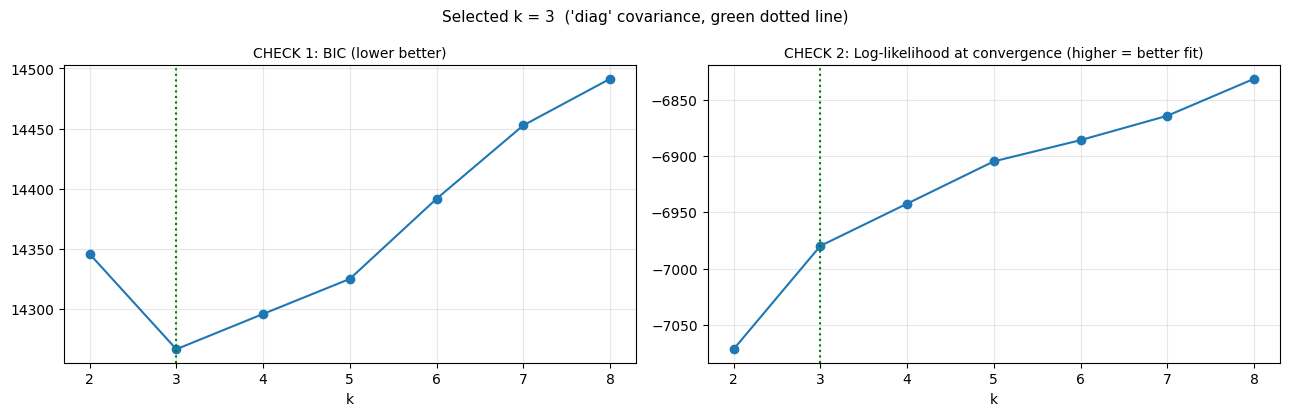

In [45]:
sel_k, sel_cov = int(chosen_row['k']), chosen_row['covariance_type']
sub = results_df[(results_df['covariance_type'] == sel_cov) & results_df['converged']].sort_values('k')

specs = [('bic', 'CHECK 1: BIC (lower better)'),
         ('log_likelihood', 'CHECK 2: Log-likelihood at convergence (higher = better fit)')]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (col, title) in zip(axes, specs):
    ax.plot(sub['k'], sub[col], marker='o', color='C0')
    ax.axvline(sel_k, color='green', ls=':', lw=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('k')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
fig.suptitle(f"Selected k = {sel_k}  ('{sel_cov}' covariance, green dotted line)", fontsize=11)
plt.tight_layout()
plt.show()

In [46]:
best_k, best_covariance_type = sel_k, sel_cov
print(f"Selected k = {best_k}, covariance_type = '{best_covariance_type}'")

gmm = make_gmm(best_k, best_covariance_type)
gmm_clusters = pd.Series(gmm.fit_predict(X), index=X_clean.index, name='gmm_cluster')
print("Converged:", gmm.converged_)
gmm_clusters.value_counts().sort_index()

Selected k = 3, covariance_type = 'diag'
Converged: True


,count
gmm_cluster,
0,47
1,79
2,115


In [47]:
log_lik = gmm.score(X) * X.shape[0]

M = consensus_matrix(X, best_k, best_covariance_type)
mk = cluster_consensus(M, gmm_clusters.values, n_clusters=best_k)

print(f"BIC: {gmm.bic(X):.2f}  (lower is better)")
print(f"Log-likelihood: {log_lik:.2f}  (converged: {gmm.converged_}, {gmm.n_iter_} iterations)")
print(f"Cluster consensus (mean): {np.nanmean(mk):.4f}  (least stable cluster {np.nanmin(mk):.3f}; 1 = perfectly stable)")

BIC: 14266.82  (lower is better)
Log-likelihood: -6979.83  (converged: True, 13 iterations)
Cluster consensus (mean): 0.9731  (least stable cluster 0.949; 1 = perfectly stable)


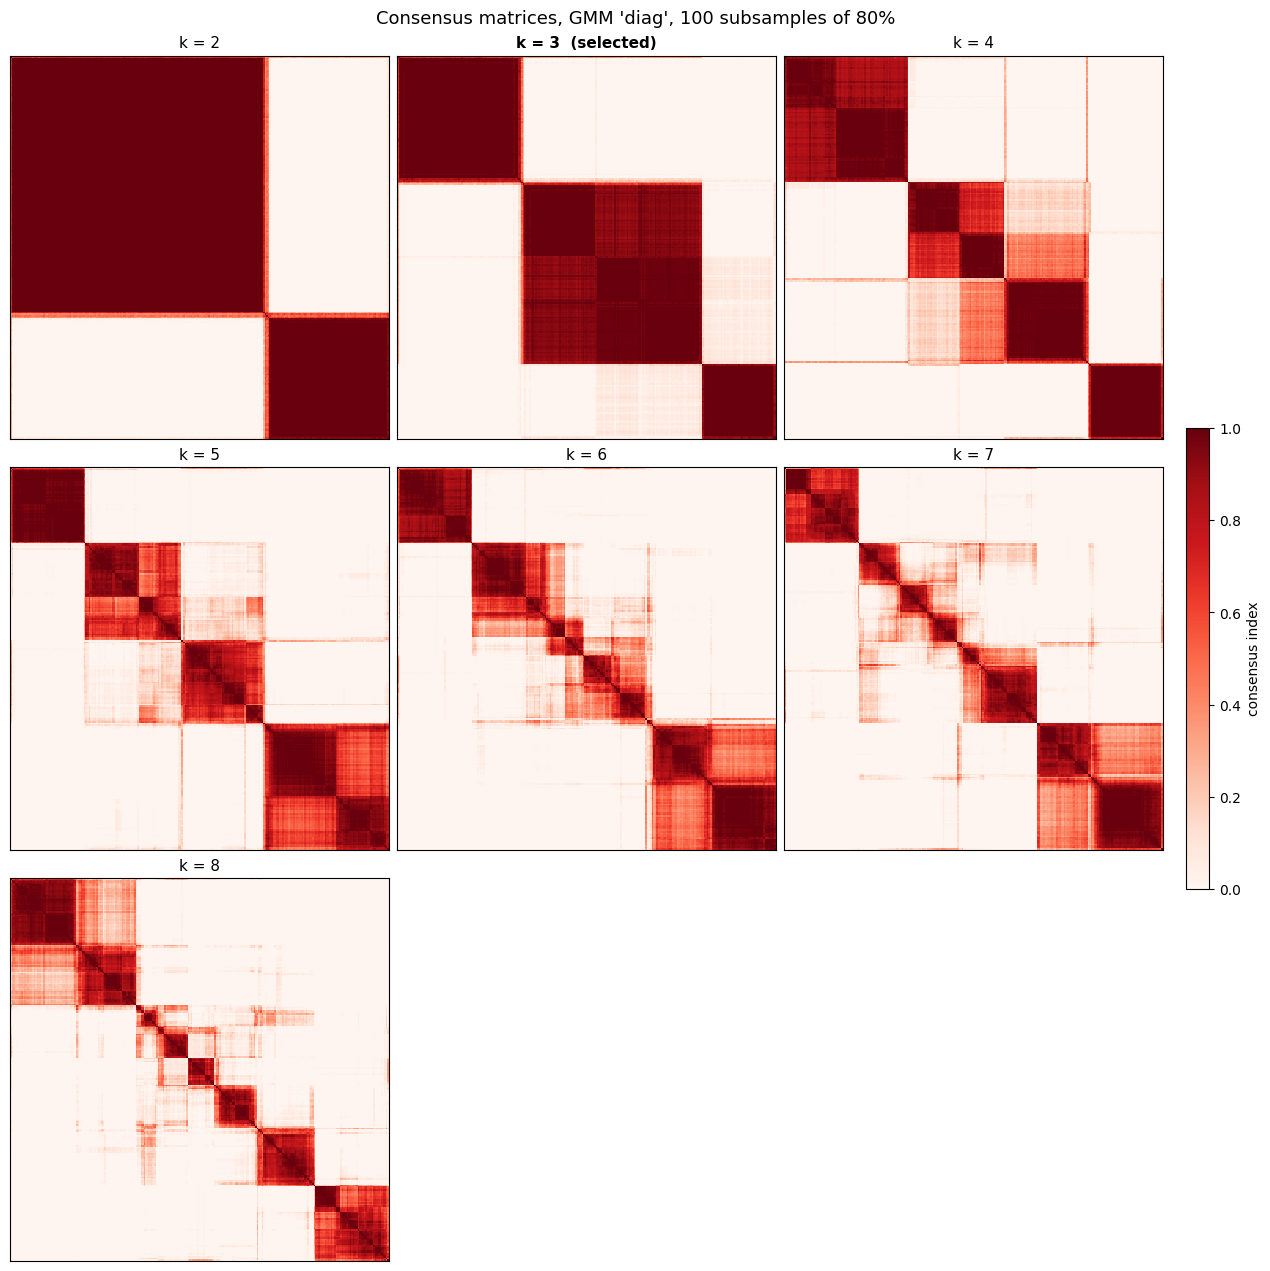

In [48]:
ks_all = list(K_RANGE)
ncols = 3; nrows = int(np.ceil(len(ks_all) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows), squeeze=False, constrained_layout=True)
for ax, kk in zip(axes.flat, ks_all):
    Mk = consensus_matrix(X, kk, best_covariance_type)
    Dk = squareform(1 - Mk, checks=False)
    order_k = leaves_list(optimal_leaf_ordering(linkage(Dk, method="average"), Dk))
    im = ax.imshow(Mk[np.ix_(order_k, order_k)], cmap="Reds", vmin=0, vmax=1, interpolation="nearest", aspect="auto")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"k = {kk}" + ("  (selected)" if kk == best_k else ""), fontsize=11,
                 fontweight="bold" if kk == best_k else "normal")
for ax in axes.flat[len(ks_all):]:
    ax.axis("off")
fig.suptitle(f"Consensus matrices, GMM '{best_covariance_type}', {N_SUBSAMPLES} subsamples of {SUBSAMPLE_FRAC:.0%}", fontsize=13)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="consensus index")
plt.show()

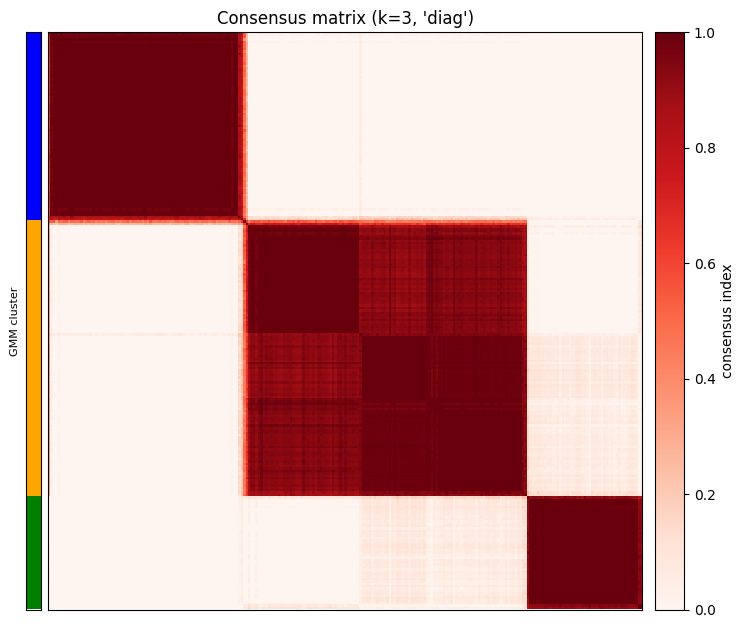

Cluster consensus m(k)  (1 = perfectly stable):
  Cluster 0 (n=47): 0.989
  Cluster 1 (n=79): 0.981
  Cluster 2 (n=115): 0.949


In [49]:
final_labels = gmm_clusters.values
Dm = squareform(1 - M, checks=False)
order = leaves_list(optimal_leaf_ordering(linkage(Dm, method="average"), Dm))
side_colors = ListedColormap(["green", "blue", "orange", "red", "purple", "brown", "pink", "grey"][:best_k])

fig, (ax_bar, ax_hm) = plt.subplots(1, 2, figsize=(8.5, 7.5), gridspec_kw={"width_ratios": [1, 40], "wspace": 0.02})
im = ax_hm.imshow(M[np.ix_(order, order)], cmap="Reds", vmin=0, vmax=1, interpolation="nearest", aspect="auto")
ax_bar.imshow(final_labels[order][:, None], cmap=side_colors, vmin=0, vmax=max(best_k - 1, 1),
              interpolation="nearest", aspect="auto")
for ax in (ax_bar, ax_hm):
    ax.set_xticks([]); ax.set_yticks([])
ax_bar.set_ylabel("GMM cluster", fontsize=8)
ax_hm.set_title(f"Consensus matrix (k={best_k}, '{best_covariance_type}')")
fig.colorbar(im, ax=ax_hm, fraction=0.046, pad=0.02, label="consensus index")
plt.show()

print("Cluster consensus m(k)  (1 = perfectly stable):")
for c in range(best_k):
    print(f"  Cluster {c} (n={int((final_labels == c).sum())}): {mk[c]:.3f}")

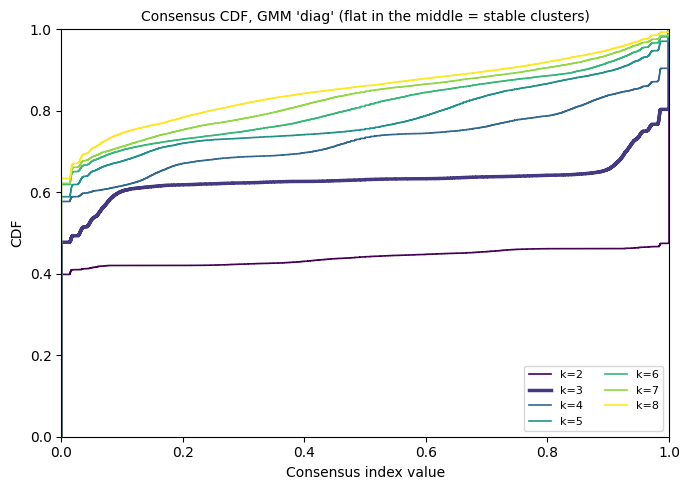

In [50]:

fig, ax = plt.subplots(figsize=(7, 5))
cmap = plt.get_cmap("viridis", len(K_RANGE))

for i, kk in enumerate(K_RANGE):
    Mk = consensus_matrix(X, kk, best_covariance_type)
    vals = np.sort(Mk[np.triu_indices(Mk.shape[0], 1)])
    cdf_vals = np.arange(1, len(vals) + 1) / len(vals)
    ax.step(vals, cdf_vals, where="post", color=cmap(i),
            lw=2.5 if kk == best_k else 1.2, label=f"k={kk}")

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Consensus index value")
ax.set_ylabel("CDF")
ax.set_title(f"Consensus CDF, GMM '{best_covariance_type}' (flat in the middle = stable clusters)", fontsize=10)
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout()
plt.show()

In [51]:
cols = [f"Cluster {c}" for c in range(max(K_RANGE))]
cc_rows, size_rows = {}, {}
for kk in K_RANGE:
    lab_k = make_gmm(kk, best_covariance_type).fit_predict(X)
    cc_rows[kk] = cluster_consensus(consensus_matrix(X, kk, best_covariance_type), lab_k, n_clusters=kk)
    size_rows[kk] = np.bincount(lab_k, minlength=kk)
cluster_consensus_table = pd.DataFrame([list(v) + [np.nan] * (len(cols) - len(v)) for v in cc_rows.values()],
                                       index=pd.Index(list(cc_rows), name="k"), columns=cols)
cluster_size_table = pd.DataFrame([list(v) + [np.nan] * (len(cols) - len(v)) for v in size_rows.values()],
                                  index=pd.Index(list(size_rows), name="k"), columns=cols)
print("Cluster consensus per cluster (blank = no such cluster at this k)")
display(cluster_consensus_table.round(3).style.format("{:.3f}", na_rep="")
        .background_gradient(cmap="Reds", vmin=0, vmax=1, subset=cols))
print("Cluster sizes (number of stocks)")
display(cluster_size_table.style.format("{:.0f}", na_rep=""))

Cluster consensus per cluster (blank = no such cluster at this k)


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7
k,,,,,,,,
2,0.977,0.987,,,,,,
3,0.989,0.981,0.949,,,,,
4,0.953,0.993,0.977,0.571,,,,
5,0.887,0.966,0.973,0.466,0.908,,,
6,0.502,0.877,0.870,0.964,0.567,0.923,,
7,0.855,0.450,0.873,0.919,0.487,0.808,0.883,
8,0.891,0.878,0.915,0.585,0.765,0.559,0.616,0.846


Cluster sizes (number of stocks)


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7
k,,,,,,,,
2,78,163,,,,,,
3,47,79,115,,,,,
4,36,41,47,117,,,,
5,32,41,46,86,36,,,
6,47,22,37,41,48,46,,
7,34,26,17,44,39,47,34,
8,15,22,16,81,37,26,15,29


In [52]:
probabilities = gmm.predict_proba(X)
maximum_probability = probabilities.max(axis=1)

uncertainty = pd.DataFrame({
    'cluster': gmm_clusters,
    'membership_probability': maximum_probability,
    'uncertain': maximum_probability < 0.70
}, index=X_clean.index)

print(uncertainty.sort_values('membership_probability').head(15))
print("Number of uncertain assignments (max posterior < 0.70):", int(uncertainty['uncertain'].sum()))

        cluster  membership_probability  uncertain
Ticker                                            
AIE.L         2                0.517639       True
ASL.L         1                0.559036       True
RTW.L         1                0.621204       True
QLT.L         1                0.637774       True
FGP.L         2                0.668803       True
ENOG.L        0                0.744200      False
USA.L         1                0.758046      False
IPO.L         2                0.778225      False
DSCV.L        2                0.781770      False
MGAM.L        0                0.803692      False
MRC.L         1                0.813340      False
SUPR.L        0                0.829765      False
PCGH.L        2                0.830274      False
GRG.L         2                0.832573      False
ASHM.L        2                0.853045      False
Number of uncertain assignments (max posterior < 0.70): 5


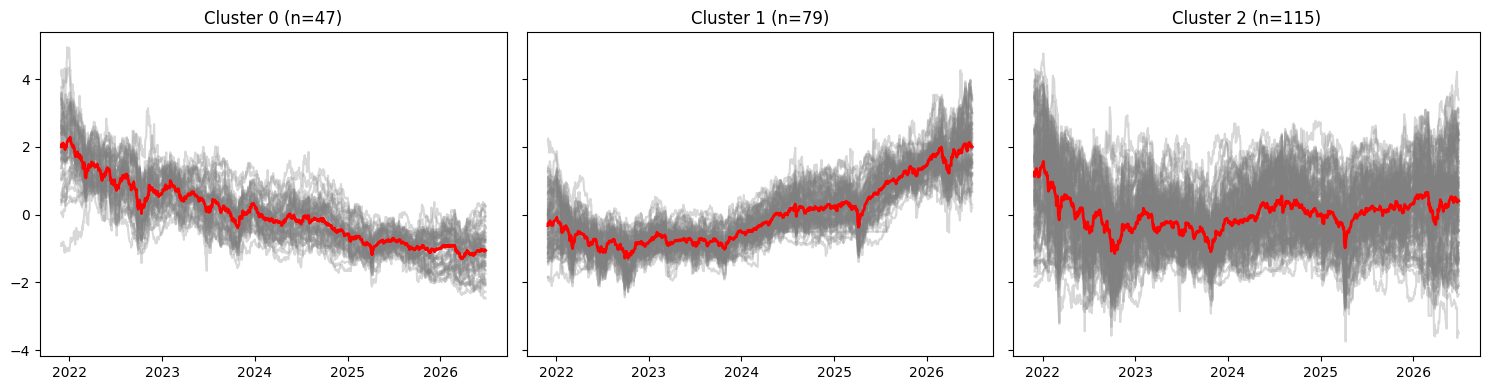

In [53]:
unique_clusters = sorted(gmm_clusters.unique())
fig, axes = plt.subplots(1, len(unique_clusters), figsize=(5 * len(unique_clusters), 4), sharey=True, squeeze=False)
for ax, c in zip(axes[0], unique_clusters):
    members = gmm_clusters[gmm_clusters == c].index
    for t in members:
        ax.plot(X_clean.columns, X_clean.loc[t], alpha=0.3, color='gray')
    ax.plot(X_clean.columns, X_clean.loc[members].mean(axis=0), color='red', linewidth=2)
    ax.set_title(f'Cluster {c} (n={len(members)})')
plt.tight_layout(); plt.show()

In [54]:
for c in sorted(gmm_clusters.unique()):
    tickers = sorted(gmm_clusters[gmm_clusters == c].index)
    print(f"Cluster {c} (n={len(tickers)}):")
    print(textwrap.fill(', '.join(tickers), width=100))
    print()

Cluster 0 (n=47):
AML.L, BME.L, BSIF.L, BYG.L, CBG.L, CVSG.L, DLN.L, DOCS.L, DOM.L, ENOG.L, FGEN.L, GBG.L, GCP.L,
GPE.L, GRI.L, HAS.L, HICL.L, INPP.L, KNOS.L, MGAM.L, MNDI.L, OCDO.L, ONT.L, PAGE.L, PETS.L, PHP.L,
PNN.L, RS1.L, SAFE.L, SEIT.L, SEQI.L, SMWH.L, SSPG.L, SUPR.L, SYNC.L, TATE.L, THG.L, TPK.L, TRIG.L,
UKW.L, UTG.L, VCT.L, WIZZ.L, WKP.L, WOSG.L, WPP.L, XPP.L

Cluster 1 (n=79):
AAS.L, AEP.L, AGT.L, AJB.L, ASL.L, ATR.L, ATT.L, ATYM.L, AVON.L, BAG.L, BBY.L, BNKR.L, BPCR.L,
BUT.L, CHG.L, CLDN.L, COST.L, CTY.L, CURY.L, CWK.L, EDIN.L, ELM.L, ESCT.L, FAN.L, FCH.L, FEML.L,
FEV.L, FSV.L, GDWN.L, GFRD.L, GNC.L, GSCT.L, HANA.L, HILS.L, HOC.L, HRI.L, HVPE.L, IAD.L, ICGT.L,
IPF.L, JAM.L, JCH.L, JEDT.L, JEGI.L, JEMI.L, JFJ.L, JGGI.L, JMGI.L, JTC.L, KIE.L, KLR.L, LWDB.L,
MGNS.L, MNKS.L, MRC.L, MTO.L, MYI.L, OCI.L, PAF.L, PAG.L, PFD.L, PIN.L, PLUS.L, PNL.L, PPET.L,
QLT.L, QQ.L, RTW.L, SDP.L, SNR.L, SOI.L, SRP.L, TBCG.L, TCAP.L, TEM.L, TMPL.L, UEM.L, USA.L, XPS.L

Cluster 2 (n=115):
3IN.L, AIE